In [1]:
from dataclasses import dataclass
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

In [2]:
# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

In [3]:
@dataclass
class TwinParams:
    # System parameters and physical constants for the VFD Centrifugal Pump Digital Twin.
    # Operating limits
    min_rpm: float = 800.0  # Minimum operational speed [rpm]
    max_rpm: float = 1800.0  # Maximum operational speed [rpm]
    vfd_ramp_rate: float = (
        2000.0  # Acceleration / deceleration slew rate limit [rpm/s]
    )
    dt: float = 0.1  # Simulation time step [s]
    rated_power_kw: float = 15.0  # Motor rated electrical power [kW]
    # Pump Curve Constants: H_pump(Q, N) = H0 * (N/N1)^2 - k * Q^2
    H0: float = 41.0  # Shutoff head at design speed [m]
    K_PUMP: float = 0.010  # Pump internal friction coefficient [m/(m^3/h)^2]
    N_DESIGN: float = 1800.0  # Rated design speed N1 [rpm]
    # System Piping Curve Constants: H_sys(Q) = H_static + K_sys * Q^2
    H_STATIC: float = 6.0  # Static elevation head [m]
    K_SYS: float = 0.012  # Piping friction coefficient [m/(m^3/h)^2]
    # Sensor characteristics
    sensor_noise_std: float = 0.25  # Gaussian noise standard deviation [m]

In [4]:
params = TwinParams()
print(
    f"Digital Twin Parameters Initialized: Speed Range"
    f" [{params.min_rpm:.0f}, {params.max_rpm:.0f}] rpm, VFD Ramp:"
    f" {params.vfd_ramp_rate:.0f} rpm/s"
)

Digital Twin Parameters Initialized: Speed Range [800, 1800] rpm, VFD Ramp: 2000 rpm/s


In [5]:
class SimulatedPressureSensor:
    # Data Ingestion Module: Simulates telemetry by injecting realistic Gaussian turbulence noise.
    def __init__(self, noise_std: float = 0.25):
        self.noise_std = noise_std
    
    def read_head(self, H_ideal: float) -> float:
        # Ingests mathematical true head and returns noisy measured head
        noise = np.random.normal(0.0, self.noise_std)
        return float(H_ideal + noise)

In [6]:
class PumpTwin:
  # Physical Plant & VFD Hardware Orchestrator.
    def __init__(self, p: TwinParams):
        self.p = p
        self.current_rpm = p.min_rpm

    def solve_operating_point(self, rpm: float) -> tuple[float, float]:
        # Finds intersection of Pump Curve and System Curve:
        # H_pump(Q, N) = H_sys(Q) -> (k + K_sys)*Q^2 = H0*(N/N1)^2 - H_static
        rpm = max(self.p.min_rpm, min(self.p.max_rpm, rpm))
        speed_ratio_sq = (rpm / self.p.N_DESIGN) ** 2
        shutoff_head = self.p.H0 * speed_ratio_sq
        # Prevent negative flow if head is lower than static lift
        head_diff = shutoff_head - self.p.H_STATIC
        if head_diff <= 0:
            return 0.0, float(self.p.H_STATIC)
        # Intersection flow Q [m^3/h]
        Q = np.sqrt(head_diff / (self.p.K_PUMP + self.p.K_SYS))
        # Operating Head H [m]
        H_ideal = self.p.H_STATIC + self.p.K_SYS * (Q**2)
        return float(Q), float(H_ideal)
    
    def estimate_power_kw(self, rpm: float) -> float:
        # Power follows cubic affinity law: P proportional to (N/N1)^3.
        return float(self.p.rated_power_kw * (rpm / self.p.N_DESIGN) ** 3)
    
    def vfd_apply(self, N_cmd: float) -> float:
        # Enforces min/max rpm clamps and mechanical acceleration/deceleration slew rate limit.
        # Clamp to allowable physical speed bounds
        target_rpm = max(self.p.min_rpm, min(self.p.max_rpm, N_cmd))
        # Enforce acceleration limit (e.g., 2000 rpm/s * dt = max 200 rpm per step)
        max_delta = self.p.vfd_ramp_rate * self.p.dt
        delta = target_rpm - self.current_rpm
        clamped_delta = np.clip(delta, -max_delta, max_delta)
        self.current_rpm += clamped_delta
        return float(self.current_rpm)
    
    @staticmethod
    def solve_analytical_rpm(H_sp: float, p: TwinParams) -> float:
        # Computes exact mathematical baseline RPM required to hit target head H_sp.
        if H_sp <= p.H_STATIC:
            return p.min_rpm
        # Required flow on system curve at H_sp
        Q_req_sq = (H_sp - p.H_STATIC) / p.K_SYS
        # 2. Invert pump curve to solve for (N/N1)^2
        speed_sq = (H_sp + p.K_PUMP * Q_req_sq) / p.H0
        analytical_rpm = p.N_DESIGN * np.sqrt(speed_sq)
        return float(np.clip(analytical_rpm, p.min_rpm, p.max_rpm))

In [7]:
class DynamicControllerPINN(nn.Module):
    # 3-input MLP replacing the traditional PI controller: [H_sp, N_curr, H_meas] -> N_cmd.
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.net(x)

In [8]:
# Generate 5,000 Synthetic Training Samples
print("Generating 5,000 synthetic state-aware samples across  rpm...")
sample_rpm = np.random.uniform(params.min_rpm, params.max_rpm, 5000)
temp_plant = PumpTwin(params)
heads = []
for rpm in sample_rpm:
    _, h = temp_plant.solve_operating_point(rpm)
    heads.append(h)
heads = np.array(heads)
# Add random perturbations to simulate dynamic system states
current_rpm_samples = np.clip(
    sample_rpm + np.random.uniform(-100, 100, 5000),
    params.min_rpm,
    params.max_rpm,
)

current_head_samples = np.clip(
    heads + np.random.normal(0, params.sensor_noise_std, 5000), 7.0, 26.0
)

target_head_samples = heads  # Target is the steady-state operating head
# Feature matrix: [H_sp, N_curr, H_meas]
X_train_raw = np.column_stack(
    (target_head_samples, current_rpm_samples, current_head_samples)
)

y_train_raw = sample_rpm.reshape(-1, 1)
# Normalization scalers for stable neural net training
X_mean, X_std = X_train_raw.mean(axis=0), X_train_raw.std(axis=0)
y_mean, y_std = y_train_raw.mean(), y_train_raw.std()
X_train_t = torch.tensor(
    (X_train_raw - X_mean) / X_std, dtype=torch.float32
)  # (5000, 3)
y_train_t = torch.tensor((y_train_raw - y_mean) / y_std, dtype=torch.float32)

Generating 5,000 synthetic state-aware samples across  rpm...


In [13]:
# Physics-Informed Training Loop
pinn_controller = DynamicControllerPINN()
optimizer = optim.Adam(pinn_controller.parameters(), lr=1e-3)
mse_loss = nn.MSELoss()
# Differentiable constants for physics loss
H0_t = torch.tensor(params.H0, dtype=torch.float32)
N1_t = torch.tensor(params.N_DESIGN, dtype=torch.float32)
H_stat_t = torch.tensor(params.H_STATIC, dtype=torch.float32)
K_comb_t = torch.tensor(params.K_PUMP + params.K_SYS, dtype=torch.float32)
K_sys_t = torch.tensor(params.K_SYS, dtype=torch.float32)
EPOCHS = 1000
PHYSICS_WEIGHT = 10.0  # Heavily penalize deviation from target setpoint
print(
    f"Training PINN Controller ({EPOCHS} epochs, Physics Weight ="
    f" {PHYSICS_WEIGHT})..."
)
for epoch in range(1, EPOCHS + 1):
    optimizer.zero_grad()
    # Supervised Data Loss (MSE of predicted vs true RPM)
    pred_norm_rpm = pinn_controller(X_train_t)
    loss_data = mse_loss(pred_norm_rpm, y_train_t)
    # Differentiable Physics Loss
    # Unscale predicted RPM back to physical units
    pred_rpm = pred_norm_rpm * y_std + y_mean
    pred_rpm = torch.clamp(pred_rpm, min=params.min_rpm, max=params.max_rpm)
    # Pass predicted RPM through pump & system intersection equations
    shutoff_h = H0_t * ((pred_rpm / N1_t) ** 2)
    Q_sq = torch.clamp(shutoff_h - H_stat_t, min=0.0) / K_comb_t
    H_theoretical = H_stat_t + K_sys_t * Q_sq
    # Target head setpoint
    target_h = torch.tensor(
        target_head_samples, dtype=torch.float32
    ).unsqueeze(1)
    loss_physics = torch.mean((H_theoretical - target_h) ** 2)
    # Total Combined Loss
    total_loss = loss_data + PHYSICS_WEIGHT * loss_physics
    total_loss.backward()
    optimizer.step()
    if epoch % 200 == 0 or epoch == 1:
        print(
            f"Epoch {epoch:4d}/{EPOCHS} | Total Loss: {total_loss.item():.4f} |"
            f" Data MSE: {loss_data.item():.4f} | Phys MSE:"
            f" {loss_physics.item():.4f}"
        )

print("PINN Controller Training Complete!\n")
pinn_controller.eval()

Training PINN Controller (1000 epochs, Physics Weight = 10.0)...
Epoch    1/1000 | Total Loss: 345.5751 | Data MSE: 1.2447 | Phys MSE: 34.4330
Epoch  200/1000 | Total Loss: 0.2907 | Data MSE: 0.0013 | Phys MSE: 0.0289
Epoch  400/1000 | Total Loss: 0.0953 | Data MSE: 0.0004 | Phys MSE: 0.0095
Epoch  600/1000 | Total Loss: 0.0505 | Data MSE: 0.0002 | Phys MSE: 0.0050
Epoch  800/1000 | Total Loss: 0.0236 | Data MSE: 0.0001 | Phys MSE: 0.0024
Epoch 1000/1000 | Total Loss: 0.0089 | Data MSE: 0.0000 | Phys MSE: 0.0009
PINN Controller Training Complete!



DynamicControllerPINN(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [14]:
# Instantiate Simulation Components
plant = PumpTwin(params)
sensor = SimulatedPressureSensor(noise_std=params.sensor_noise_std)
# Simulation Timing
SIM_TIME = 60.0  # seconds
time_steps = np.arange(0.0, SIM_TIME, params.dt)
# State initialization
plant.current_rpm = params.min_rpm  # Start from minimum speed (800 rpm)
H_meas = 7.15  # Initial measured head
# Cumulative energy tracking
cumulative_energy_kwh = 0.0
cumulative_volume_m3 = 0.0
# Telemetry log
logs = []

print("Running 60-second Closed-Loop Digital Twin Simulation...")
for t in time_steps:
    # Step Change Setpoint: 25m from t=0 to 1s, then drops to 15m
    H_sp = 25.0 if t < 1.0 else 15.0
    # Physics Model: Operating point from current actual RPM
    Q, H_ideal = plant.solve_operating_point(plant.current_rpm)
    # Data Ingestion: Sensor reads ideal head with injected Gaussian noise
    H_meas = sensor.read_head(H_ideal)
    # PINN Controller: Predicts required RPM command from noisy sensor
    with torch.no_grad():
        x_input = np.array([[H_sp, plant.current_rpm, H_meas]])
        x_norm = torch.tensor((x_input - X_mean) / X_std, dtype=torch.float32)
        N_cmd_norm = pinn_controller(x_norm).item()
        N_cmd = float(N_cmd_norm * y_std + y_mean)
    # Exact Mathematical Baseline (Analytical inverse physics command)
    N_analytical = PumpTwin.solve_analytical_rpm(H_sp, params)
    # VFD Actuator: Enforces 2000 rpm/s slew rate and clamps
    actual_rpm = plant.vfd_apply(N_cmd)
    # Energy & Volume Integration
    power_kw = plant.estimate_power_kw(actual_rpm)
    cumulative_energy_kwh += power_kw * (params.dt / 3600.0)
    cumulative_volume_m3 += Q * (params.dt / 3600.0)
    specific_energy = (
        cumulative_energy_kwh / cumulative_volume_m3
        if cumulative_volume_m3 > 0
        else 0.0
    )

    # Record Telemetry
    logs.append({
        "time": t,
        "H_sp": H_sp,
        "H_ideal": H_ideal,
        "H_meas": H_meas,
        "Q": Q,
        "rpm": actual_rpm,
        "N_cmd": N_cmd,
        "N_analytical": N_analytical,
        "power_kw": power_kw,
        "energy_kwh": cumulative_energy_kwh,
        "volume_m3": cumulative_volume_m3,
        "specific_energy": specific_energy,
    })

Running 60-second Closed-Loop Digital Twin Simulation...


In [15]:
df_sim = pd.DataFrame(logs)
print("Simulation Complete!")
print("\n--- Final Simulation State (t = 59.9s) ---")
print(f"Speed: {df_sim['rpm'].iloc[-1]:.1f} rpm (PINN Cmd: {df_sim['N_cmd'].iloc[-1]:.1f} rpm, Math: {df_sim['N_analytical'].iloc[-1]:.1f} rpm)")
print(f"Head:  {df_sim['H_meas'].iloc[-1]:.2f} m (Setpoint: {df_sim['H_sp'].iloc[-1]:.2f} m)")
print(f"Flow:  {df_sim['Q'].iloc[-1]:.2f} m^3/h | Power: {df_sim['power_kw'].iloc[-1]:.2f} kW")
print(f"Specific Energy: {df_sim['specific_energy'].iloc[-1]:.3f} kWh/m^3")

Simulation Complete!

--- Final Simulation State (t = 59.9s) ---
Speed: 1331.8 rpm (PINN Cmd: 1331.8 rpm, Math: 1333.4 rpm)
Head:  14.66 m (Setpoint: 15.00 m)
Flow:  27.42 m^3/h | Power: 6.08 kW
Specific Energy: 0.225 kWh/m^3


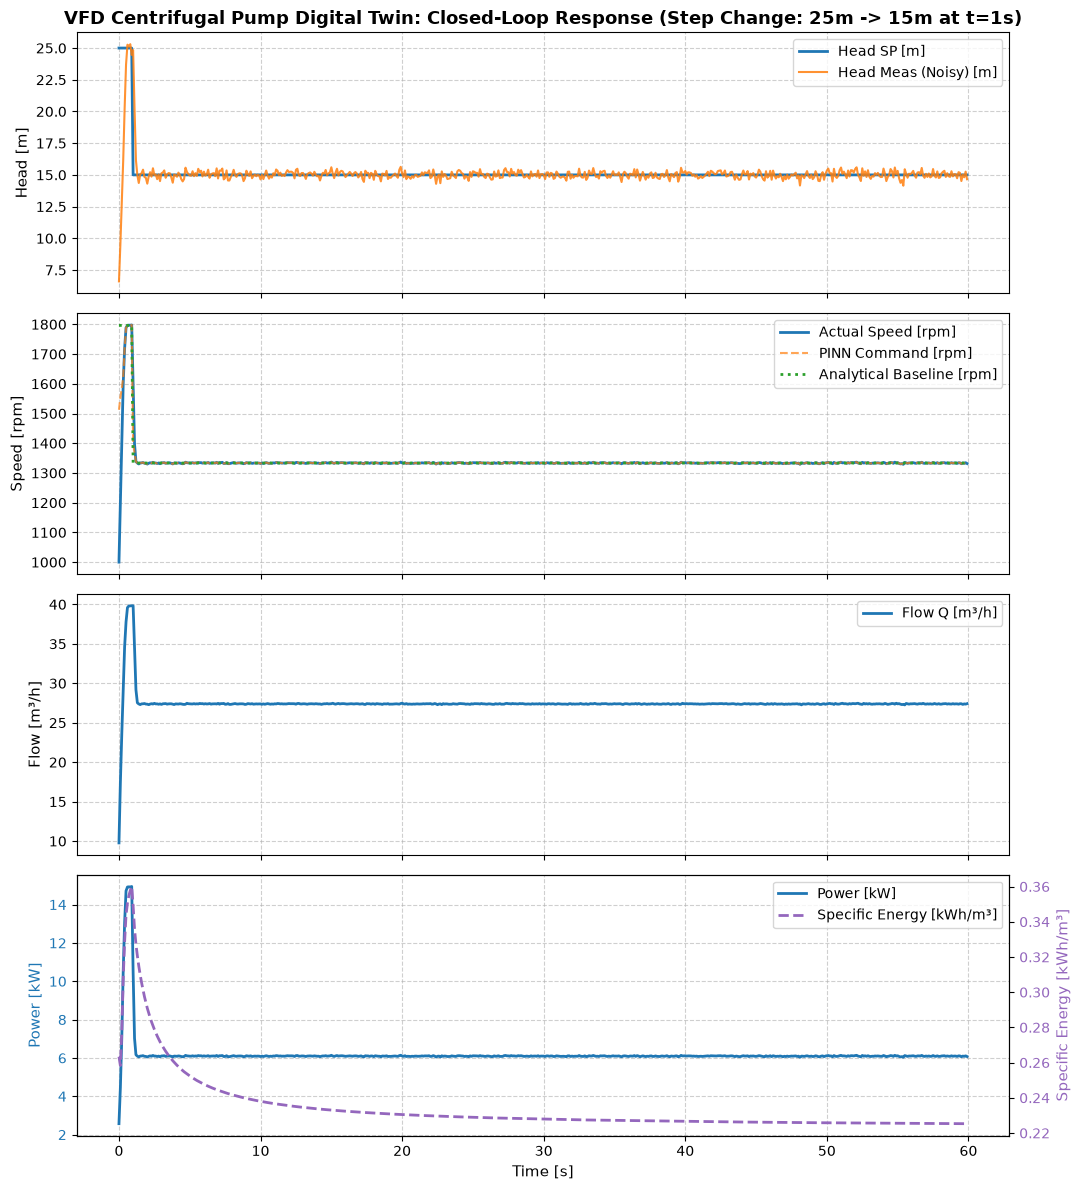

In [16]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(11, 12), sharex=True)

# Head Tracking
ax1.plot(
    df_sim["time"],
    df_sim["H_sp"],
    "tab:blue",
    linewidth=2,
    label="Head SP [m]",
)
ax1.plot(
    df_sim["time"],
    df_sim["H_meas"],
    "tab:orange",
    alpha=0.85,
    label="Head Meas (Noisy) [m]",
)
ax1.set_ylabel("Head [m]", fontsize=11)
ax1.set_title(
    "VFD Centrifugal Pump Digital Twin: Closed-Loop Response (Step Change: 25m"
    " -> 15m at t=1s)",
    fontsize=13,
    fontweight="bold",
)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="upper right")

# Speed Tracking (Actual, PINN Command, & Analytical Validation)
ax2.plot(
    df_sim["time"],
    df_sim["rpm"],
    "tab:blue",
    linewidth=2,
    label="Actual Speed [rpm]",
)
ax2.plot(
    df_sim["time"],
    df_sim["N_cmd"],
    "tab:orange",
    linestyle="--",
    alpha=0.7,
    label="PINN Command [rpm]",
)
ax2.plot(
    df_sim["time"],
    df_sim["N_analytical"],
    "tab:green",
    linestyle=":",
    linewidth=2,
    label="Analytical Baseline [rpm]",
)
ax2.set_ylabel("Speed [rpm]", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right")

# Flow Rate
ax3.plot(
    df_sim["time"],
    df_sim["Q"],
    "tab:blue",
    linewidth=2,
    label="Flow Q [m³/h]",
)
ax3.set_ylabel("Flow [m³/h]", fontsize=11)
ax3.grid(True, linestyle="--", alpha=0.6)
ax3.legend(loc="upper right")

# Power & Specific Energy (Dual Y-Axis)
color_p = "tab:blue"
ax4.plot(
    df_sim["time"],
    df_sim["power_kw"],
    color=color_p,
    linewidth=2,
    label="Power [kW]",
)
ax4.set_xlabel("Time [s]", fontsize=11)
ax4.set_ylabel("Power [kW]", color=color_p, fontsize=11)
ax4.tick_params(axis="y", labelcolor=color_p)
ax4.grid(True, linestyle="--", alpha=0.6)

ax4_twin = ax4.twinx()
color_se = "tab:purple"
ax4_twin.plot(
    df_sim["time"],
    df_sim["specific_energy"],
    color=color_se,
    linestyle="--",
    linewidth=2,
    label="Specific Energy [kWh/m³]",
)
ax4_twin.set_ylabel(
    "Specific Energy [kWh/m³]", color=color_se, fontsize=11
)
ax4_twin.tick_params(axis="y", labelcolor=color_se)

# Combine legends for subplot 4
lines1, labels1 = ax4.get_legend_handles_labels()
lines2, labels2 = ax4_twin.get_legend_handles_labels()
ax4.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.tight_layout()
plt.show()

Running Steady-State Setpoint Sweep...

--- Steady-State Energy Map ---
 setpoint_m    rpm  flow_m3_h  power_kw  specific_kwh_per_m3
       18.0 1000.0   9.767212  2.572016             0.263332
       20.0 1000.0   9.767212  2.572016             0.263332
       22.0 1000.0   9.767212  2.572016             0.263332
       25.0 1000.0   9.767212  2.572016             0.263332
       28.0 1000.0   9.767212  2.572016             0.263332


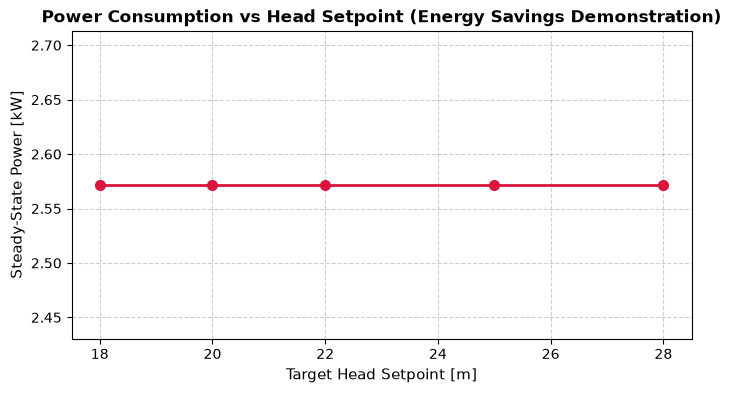

In [17]:
sweep_setpoints = [18.0, 20.0, 22.0, 25.0, 28.0]
sweep_results = []

print("Running Steady-State Setpoint Sweep...")
for sp in sweep_setpoints:
    temp_plant = PumpTwin(params)
    temp_plant.current_rpm = params.min_rpm
    cum_e = 0.0
    cum_v = 0.0
    
    # Run for 40 seconds to reach steady state
    for step_i in range(int(40.0 / params.dt)):
        Q, H_ideal = temp_plant.solve_operating_point(temp_plant.current_rpm)
        H_meas = sensor.read_head(H_ideal)
    
    with torch.no_grad():
        inp = np.array([[sp, temp_plant.current_rpm, H_meas]])
        inp_norm = torch.tensor((inp - X_mean) / X_std, dtype=torch.float32)
        cmd_norm = pinn_controller(inp_norm).item()
        cmd_rpm = float(cmd_norm * y_std + y_mean)
    
    rpm_now = temp_plant.vfd_apply(cmd_rpm)
    p_kw = temp_plant.estimate_power_kw(rpm_now)
    cum_e += p_kw * (params.dt / 3600.0)
    cum_v += Q * (params.dt / 3600.0)
    
    sweep_results.append({
        "setpoint_m": sp,
        "rpm": rpm_now,
        "flow_m3_h": Q,
        "power_kw": p_kw,
        "specific_kwh_per_m3": cum_e / cum_v if cum_v > 0 else 0.0,
    })

df_sweep = pd.DataFrame(sweep_results)
print("\n--- Steady-State Energy Map ---")
print(df_sweep.to_string(index=False))

# Plot Power vs Setpoint
plt.figure(figsize=(8, 4))
plt.plot(
    df_sweep["setpoint_m"],
    df_sweep["power_kw"],
    "o-",
    color="crimson",
    linewidth=2,
    markersize=7,
)
plt.title(
    "Power Consumption vs Head Setpoint (Energy Savings Demonstration)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Target Head Setpoint [m]", fontsize=11)
plt.ylabel("Steady-State Power [kW]", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()